# Regression 

## Setup

### Imports

In [1]:
import os
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

import ipywidgets as widgets
from IPython.display import display

### Load Datasets

In [2]:
base_dir = os.path.join(os.getcwd(), '..')
processed_data_dir = os.path.join(base_dir, 'processed_data')

open_meteo_filepath = os.path.join(processed_data_dir, 'open_meteo_processed_data.csv')
open_meteo_df = pd.read_csv(open_meteo_filepath, parse_dates=['datetime'])

ausgrid_filepath = os.path.join(processed_data_dir, 'ausgrid_processed_data.csv')
ausgrid_df = pd.read_csv(ausgrid_filepath, parse_dates=['datetime'])

### Training-Testing Dataset Creation

We will create two testing datasets. The first will evaluate model performance on unseen customers, using models trained to predict PV generation generally rather than for specific customers. It will hold out all three years of data for a subset of customers.

The second will evaluate model performance on unseen days for models trained separately for each customer. Its goal is to predict future generation for known customers. This dataset uses a single chronological split, so it may not include data from all seasons.

In [3]:
unseen_customer_testing_split = 0.15
unseen_datetime_testing_split = 0.15

First, we merse the smart-meter data and weather data on `datetime`.

In [42]:
data = ausgrid_df.merge(open_meteo_df, on='datetime', how='left').sort_values('datetime')

# Check each customer's timestamps against the full expected sequence
expected_timestamps = pd.date_range(
    start=data["datetime"].min(),
    end=data["datetime"].max(),
    freq="30min"
)

customers_with_missing_rows = []

for customer, customer_data in data.groupby("Customer", sort=False):
    customer_timestamps = pd.DatetimeIndex(customer_data["datetime"].unique())
    missing = expected_timestamps.difference(customer_timestamps)
    if not missing.empty: customers_with_missing_rows.append(customer)

# Remove customers with missing timestamps
data = data.loc[~data["Customer"].isin(customers_with_missing_rows)].copy()

print(f"Removed {len(customers_with_missing_rows)} customers")
print(f"Remaining data: {len(data):,} rows, {data['Customer'].nunique()} customers")

Number of Customers with Missing Timestamps: 1
Removed 1 customers
Remaining data: 15,729,792 rows, 299 customers


First, we choose a subset of the customers to hold out. We want to choose a group of customers whose combined data is near the target dataset size specified by `data`. `cumulative_customer_rows` is the running total of rows for shuffled customers. This will allow us to determine how many customers to hold out so their combined rows are closest to the target test-set size.

In [44]:
rng = np.random.default_rng(42)

customer_counts = data.groupby("Customer", sort=False).size()
shuffled_customers = rng.permutation(customer_counts.index.to_numpy())
customer_counts_shuffled = customer_counts.loc[shuffled_customers]
cumulative_customer_rows = customer_counts_shuffled.cumsum()

display(cumulative_customer_rows.rename("Cumulative rows").to_frame().head())

,Cumulative rows
Customer,
185,52608
164,105216
24,157824
294,210432
292,263040


Next, we calculate the desired number of rows in the unseen-customer test set. We find how many shuffled customers give a cumulative row count closest to that target, and convert this into the number of customers to select. Finally, we select that many customers from the start of the shuffled list. Their rows become the test set.

In [45]:
customer_target_rows = unseen_customer_testing_split * len(data)
customer_count_end = (cumulative_customer_rows - customer_target_rows).abs().argmin() + 1
customer_test_customers = shuffled_customers[:customer_count_end]

display(pd.DataFrame({
    "Target rows": [customer_target_rows],
    "Actual rows": [cumulative_customer_rows.iloc[customer_count_end - 1]],
    "Customers selected": [customer_count_end],
}).style.hide(axis='index'))

print(f"Customers selected for test dataset: {sorted(map(int, customer_test_customers))}")

Target rows,Actual rows,Customers selected
2359468.800000,2367360,45


Customers selected for test dataset: [1, 8, 13, 24, 33, 45, 54, 62, 67, 68, 79, 84, 87, 88, 91, 102, 113, 115, 116, 118, 125, 126, 127, 141, 144, 156, 159, 164, 178, 185, 197, 205, 206, 219, 225, 237, 240, 245, 272, 277, 281, 292, 294, 299, 300]


Next we create a Boolean mask `True` for rows whose customer is in the test-customer list, `False` otherwise. We then copy test-customer rows into a separate dataset. We flip the mask in order to select the remaining rows. 

In [46]:
customer_test_mask = data['Customer'].isin(customer_test_customers)
customer_test_data = data.loc[customer_test_mask].copy()
remaining_data = data.loc[~customer_test_mask]

print(f"Customer test data: {len(customer_test_data):,} rows, {customer_test_data['Customer'].nunique()} customers")
print(f"Remaining data: {len(remaining_data):,} rows, {remaining_data['Customer'].nunique()} customers")

Customer test data: 2,367,360 rows, 45 customers
Remaining data: 13,362,432 rows, 254 customers


Next, we create the datetime dataset.
The cumulative rows shows the total number of rows that would be in the testing dataset if the data was split at each timestamp.
this allows us to see where to split the dataset to get the testing dataset to have closest to the specified number of rows.
we calculate the number of rows we want for the test dataset, then chose the timestamp that will give closest to this number of rows.

In [47]:
rows_per_datetime = remaining_data.groupby('datetime', sort=True).size()
display(rows_per_datetime.rename('Rows Per Datetime').to_frame().head())

cumulative_tail_rows = rows_per_datetime.iloc[::-1].cumsum()
display(cumulative_tail_rows.rename('Cumulative Tail Rows').to_frame().head())

datetime_target_rows = (unseen_datetime_testing_split / (1 - unseen_customer_testing_split)) * len(remaining_data)
datetime_start = (cumulative_tail_rows.sub(datetime_target_rows).abs().idxmin())
print(f'Test Dataset Start Datetime: {datetime_start}')

,Rows Per Datetime
datetime,
2010-07-01 00:00:00,254
2010-07-01 00:30:00,254
2010-07-01 01:00:00,254
2010-07-01 01:30:00,254
2010-07-01 02:00:00,254


,Cumulative Tail Rows
datetime,
2013-06-30 23:30:00,254
2013-06-30 23:00:00,508
2013-06-30 22:30:00,762
2013-06-30 22:00:00,1016
2013-06-30 21:30:00,1270


Test Dataset Start Datetime: 2012-12-19 14:00:00


Next, we select rows on or after the start timestamp. Early rows become the training dataset. Because the training dataset now has fewer unique datetimes than the unseen customer testing set, we further trim the unseen customer testing set. Finally, we take the only the data with both unseen customers and unseen timestamps as our third testing dataset.

In [50]:
datetime_test_mask = remaining_data['datetime'] >= datetime_start
datetime_test_data = remaining_data.loc[datetime_test_mask].copy()
train_data = remaining_data.loc[~datetime_test_mask].copy()

# Keep unseen-customer test rows only for timestamps also present in the training set
train_timestamps = train_data['datetime'].unique()
customer_test_data = customer_test_data.loc[
    customer_test_data['datetime'].isin(train_timestamps)].copy()

# Hold out rows for unseen customers at timestamps excluded from training,
customer_datetime_test_mask = (
    data['Customer'].isin(customer_test_customers)
    & ~data['datetime'].isin(train_timestamps)
)
unseen_customer_datetime_test_data = data.loc[customer_datetime_test_mask].copy()

display(pd.DataFrame({
    'Dataset': [
        'Train',
        'Unseen datetime test',
        'Unseen customer test',
        'Unseen customer + datetime test'
    ],
    'Rows': [
        len(train_data),
        len(datetime_test_data),
        len(customer_test_data),
        len(unseen_customer_datetime_test_data)
    ],
    'Customers': [
        train_data['Customer'].nunique(),
        datetime_test_data['Customer'].nunique(),
        customer_test_data['Customer'].nunique(),
        unseen_customer_datetime_test_data['Customer'].nunique()
    ],
    'Unique timestamps': [
        train_data['datetime'].nunique(),
        datetime_test_data['datetime'].nunique(),
        customer_test_data['datetime'].nunique(),
        unseen_customer_datetime_test_data['datetime'].nunique()
    ]
}).style.hide(axis='index'))

Dataset,Rows,Customers,Unique timestamps
Train,11004296,254,43324
Unseen datetime test,2358136,254,9284
Unseen customer test,1949580,45,43324
Unseen customer + datetime test,417780,45,9284


## Average Curve Baseline

PV generation has daily and seasonal patterns. Daily generation is zero before sunrise, rises towards midday, then falls to zero by sunset. Seasonally, generation is typically highest in the summer, lower in the spring and fall, and lowest in winter. This regression model predicts PV generation (`Pgen`) using the historical average for that month (seasonality) and time-of-day. In short, it averages the daily PV curves for each month.

We train and evaluate the model in three scenarios. First, we train on historical generation from a set of customers and predict future generation for those same customers on unseen timestamps. Seconds, we use the same training data to predict generation for unseen customers at timestamps represented elsewhere in the data. Finally, we test on both unseen customers and unseen timestamps.

First, we convert each timestamp into a month slot (0-12) and half-hour slot (0-47).

In [52]:
def get_slots(data):
    months = data['datetime'].dt.month
    hhslots = data['datetime'].dt.hour * 2 + data['datetime'].dt.minute // 30
    return months, hhslots

train_months, train_hhslots = get_slots(train_data)
customer_test_months, customer_test_hhslots = get_slots(customer_test_data)

we create average profiles. the first finds the average daily curve (one curve per month) separately for each customer, resulting in a total of $12 \times `n_customers`$ curves. This will be used to predict pv generation for unseen datetimes in the scenario where we want to predict unseen futres dates for known customers. To get the seconds, we will average the daily curves over the customers, so that we have only 12 curves. this will be used to predict for the scenario of unseen customers, which correspond to the other two test sets. 

In [57]:
# create avg_profile_1: one average daily PV profile per customer per month
avg_profile_1 = (
    train_data[["Customer", "Pgen"]]
    .assign(
        month=train_months.to_numpy(),
        half_hour_slot=train_hhslots.to_numpy()
    )
    .groupby(["Customer", "month", "half_hour_slot"], as_index=False)["Pgen"]
    .mean()
)

# create avg_profile_2 by averaging avg_profile_1 across customers
avg_profile_2 = (
    avg_profile_1
    .groupby(["month", "half_hour_slot"], as_index=False)["Pgen"]
    .mean()
)

# display the number of daily PV curves in each profile
n_curves_1 = avg_profile_1["Customer"].nunique() * avg_profile_1["month"].nunique()
n_curves_2 = avg_profile_2["month"].nunique()

print(f"avg_profile_1: {n_curves_1} daily PV curves")
print(f"avg_profile_2: {n_curves_2} daily PV curves")

avg_profile_1: 3048 daily PV curves
avg_profile_2: 12 daily PV curves


To visualize this message, we plot each of the 12 daily pv curves from `avg_profile_2`. This shows the average seasonal difference in PV production. It is very important to note that this does not account for the substantial variation between individual customers.

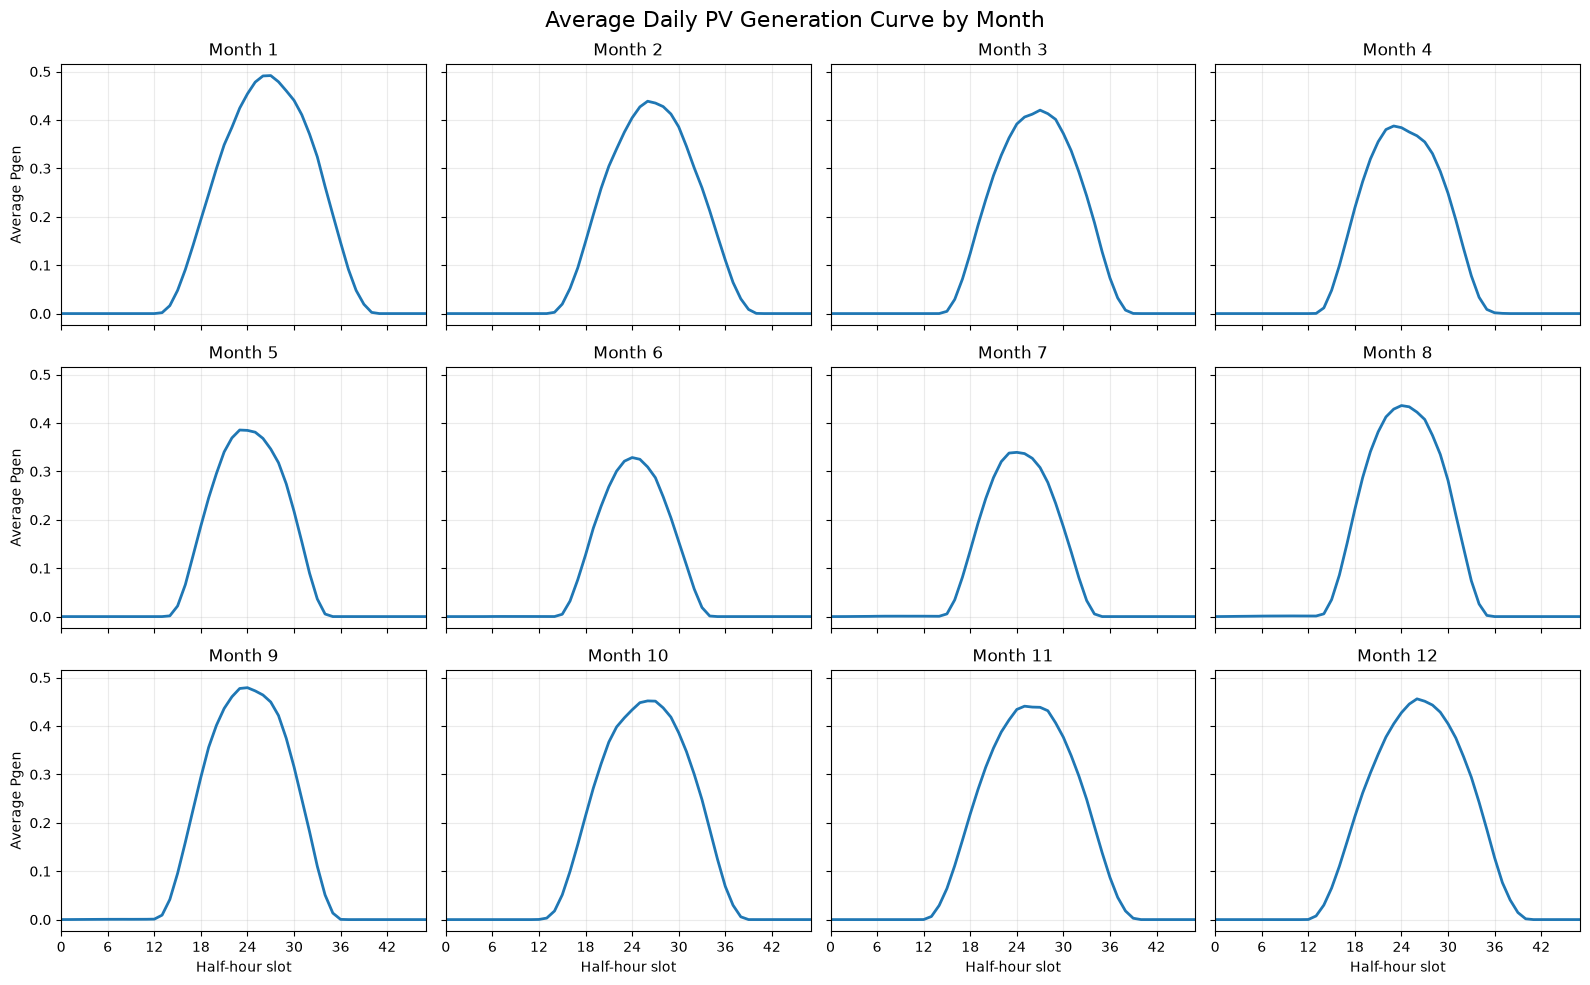

In [58]:
# Plot the average daily PV curve for each month in a single 12-panel figure
fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()

for month in range(1, 13):
    ax = axes[month - 1]
    month_data = avg_profile_2[avg_profile_2["month"] == month].sort_values("half_hour_slot")
    
    ax.plot(
        month_data["half_hour_slot"],
        month_data["Pgen"],
        color="tab:blue",
        linewidth=2
    )
    ax.set_title(f"Month {month}")
    ax.set_xlim(0, 47)
    ax.set_xticks(np.arange(0, 48, 6))
    ax.grid(alpha=0.25)

    if month in [1, 5, 9]:
        ax.set_ylabel("Average Pgen")
    if month in [9, 10, 11, 12]:
        ax.set_xlabel("Half-hour slot")

fig.suptitle("Average Daily PV Generation Curve by Month", fontsize=16)
fig.tight_layout()
plt.show()

This code predicts generation for the unseen-datetime test set using each customer's historic average profile. First, it copies the test rows' customer, timestamp, and actual Pgen values. Next, its extracts the month and half-hour-of-day slot for each timestamp, and adds these as columns.

In [61]:
# Predict Pgen for the unseen-datetime test set using each customer's average profile
datetime_test_predictions = datetime_test_data[
    ["Customer", "datetime", "Pgen"]
].copy()

test_months, test_hhslots = get_slots(datetime_test_predictions)
datetime_test_predictions["month"] = test_months.to_numpy()
datetime_test_predictions["half_hour_slot"] = test_hhslots.to_numpy()

Next, we join merge `avg_profile_1` with the `datetime_test_predictions`, renaming `avg_profile_1`'s `Pgen` to `Pgen_pred`. `validate='many_to_one` checks that each profile key has at most one match. Just in case, we drop rows missing either actual or predicted `Pgen1. We then calculate:
- MAE: Average absolute prediction error.
- RMSE: Square-root of the average squared error, which penalizes larger errors more.

In [64]:
datetime_test_predictions = datetime_test_predictions.merge(
    avg_profile_1.rename(columns={"Pgen": "Pgen_pred"}),
    on=["Customer", "month", "half_hour_slot"],
    how="left",
    validate="many_to_one")

# Evaluate rows with available actual and predicted values
valid = datetime_test_predictions[["Pgen", "Pgen_pred"]].dropna()
mae = np.mean(np.abs(valid["Pgen"] - valid["Pgen_pred"]))
rmse = np.sqrt(np.mean((valid["Pgen"] - valid["Pgen_pred"]) ** 2))

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
display(datetime_test_predictions.head())

MAE:  0.0519
RMSE: 0.1196


,Customer,datetime,Pgen,month,half_hour_slot,Pgen_pred_x,Pgen_pred_y,Pgen_pred
0,233,2012-12-19 14:00:00,0.606,12,28,0.397875,0.397875,0.397875
1,282,2012-12-19 14:00:00,0.788,12,28,0.810463,0.810463,0.810463
2,97,2012-12-19 14:00:00,0.351,12,28,0.658125,0.658125,0.658125
3,224,2012-12-19 14:00:00,0.175,12,28,0.258025,0.258025,0.258025
4,100,2012-12-19 14:00:00,0.188,12,28,0.332000,0.332000,0.332000


The function uses `avg_profile_2` to prefict generation without needing a customer-specific profile. Similar to before, we copy each test row's customer, timestamp, and actual `Pgen`, and get the month and half-hour slots. We join each row to the matching average profile to add `Pgen_pred`. We exclude rows missing actual or predicted values, then calculate MAE and RMSE. This is done on both the unseen-customer test set and the unseen-customer-and-datetime test set.

In [66]:
# Use avg_profile_2 to predict for unseen customers, with and without unseen timestamps
def predict_and_evaluate_avg_profile_2(test_data, dataset_name):
    predictions = test_data[["Customer", "datetime", "Pgen"]].copy()

    months, hhslots = get_slots(predictions)
    predictions["month"] = months.to_numpy()
    predictions["half_hour_slot"] = hhslots.to_numpy()

    predictions = predictions.merge(
        avg_profile_2.rename(columns={"Pgen": "Pgen_pred"}),
        on=["month", "half_hour_slot"],
        how="left",
        validate="many_to_one"
    )

    valid = predictions[["Pgen", "Pgen_pred"]].dropna()
    mae = np.mean(np.abs(valid["Pgen"] - valid["Pgen_pred"]))
    rmse = np.sqrt(np.mean((valid["Pgen"] - valid["Pgen_pred"]) ** 2))

    print(f"{dataset_name} — MAE: {mae:.4f}, RMSE: {rmse:.4f}")
    return predictions


customer_test_predictions = predict_and_evaluate_avg_profile_2(
    customer_test_data, "Unseen customers")

unseen_customer_datetime_test_predictions = predict_and_evaluate_avg_profile_2(
    unseen_customer_datetime_test_data, "Unseen customers and datetimes")

Unseen customers — MAE: 0.0722, RMSE: 0.1639
Unseen customers and datetimes — MAE: 0.0698, RMSE: 0.1542


In [67]:
# Summarize MAE and RMSE across all three test sets
test_predictions = {
    "Unseen datetimes": datetime_test_predictions,
    "Unseen customers": customer_test_predictions,
    "Unseen customers + datetimes": unseen_customer_datetime_test_predictions,
}

metrics = []

for dataset_name, predictions in test_predictions.items():
    valid_predictions = predictions[["Pgen", "Pgen_pred"]].dropna()
    errors = valid_predictions["Pgen"] - valid_predictions["Pgen_pred"]

    metrics.append({
        "Test set": dataset_name,
        "MAE": np.abs(errors).mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
        "Rows evaluated": len(valid_predictions),
    })

display(pd.DataFrame(metrics).style.format({
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "Rows evaluated": "{:,}",
}).hide(axis="index"))

Test set,MAE,RMSE,Rows evaluated
Unseen datetimes,0.0519,0.1196,"2,358,136"
Unseen customers,0.0722,0.1639,"1,949,580"
Unseen customers + datetimes,0.0698,0.1542,"417,780"
